In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc

def parse_comsol_data(filepath):
    """
    Parse COMSOL data file and return organized DataFrame.
    
    Parameters:
    -----------
    filepath : str
        Path to the COMSOL data file
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with columns for coordinates, physical parameters, U_in, and Sb_option
    """
    
    with open(filepath, 'r') as file:
        lines = file.readlines()
    
    # Find the header line with column names
    header_line = None
    data_start = None
    
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break
    
    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")
    
    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix
    
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = []
    
    for col in columns:
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            
            # Extract U_in value
            u_in_match = re.search(r'U_in=([0-9E.-]+)', conditions)
            u_in = float(u_in_match.group(1)) if u_in_match else None
            
            # Extract Sb_option value
            sb_match = re.search(r'Sb_option=([0-9]+)', conditions)
            sb_option = int(sb_match.group(1)) if sb_match else None
            
            parsed_columns.append({
                'original_name': col,
                'param_name': param_name,
                'u_in': u_in,
                'sb_option': sb_option
            })
        else:
            # Coordinate columns (r, z)
            parsed_columns.append({
                'original_name': col,
                'param_name': col,
                'u_in': None,
                'sb_option': None
            })
    
    # Read the data
    data_lines = lines[data_start:]
    
    # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    
    # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=[col['original_name'] for col in parsed_columns])
    
    # Reorganize data by grouping parameters by U_in and Sb_option
    organized_data = []
    
    # Get coordinate columns (r, z)
    coord_cols = [col for col in parsed_columns if col['u_in'] is None]
    
    # Get unique combinations of U_in and Sb_option
    param_cols = [col for col in parsed_columns if col['u_in'] is not None]
    unique_conditions = set((col['u_in'], col['sb_option']) for col in param_cols)
    
    for u_in, sb_option in unique_conditions:
        # Get all parameter columns for this condition
        condition_cols = [col for col in param_cols 
                         if col['u_in'] == u_in and col['sb_option'] == sb_option]
        
        # For each row in the original data
        for idx, row in df_raw.iterrows():
            # Start with coordinates
            row_data = {'r': row[coord_cols[0]['original_name']], 
                       'z': row[coord_cols[1]['original_name']]}
            
            # Add condition identifiers
            row_data['U_in'] = u_in
            row_data['Sb_option'] = sb_option
            
            # Add all parameters for this condition
            for col in condition_cols:
                param_name = col['param_name']
                # Clean up parameter names (remove units and extra info)
                clean_param_name = param_name.split('(')[0].strip()
                row_data[clean_param_name] = row[col['original_name']]
            
            organized_data.append(row_data)
    
    # Create the final organized DataFrame
    df_organized = pd.DataFrame(organized_data)
    
    # Sort by U_in, Sb_option, and spatial coordinates
    df_organized = df_organized.sort_values(['U_in', 'Sb_option', 'r', 'z']).reset_index(drop=True)
    
    return df_organized
def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth +2.5e6+1e5)  # Adding 2.5 MPa offset for lithostatic pressure at surface
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


In [2]:
def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis

In [3]:

# File path
filepath_sb_0 = 'conduit_wall_out_in_Dec01_2025_std19_mph_sol453_Colima_Cw_3_CR_15_T1273_nu_max_1e4_Sb_0.txt'

filepath_sb_4 = 'conduit_wall_out_in_Dec01_2025_std19_mph_sol453_Colima_Cw_3_CR_15_T1273_nu_max_1e4_Sb_4.txt'

filepath_sb_6 = 'conduit_wall_out_in_Dec01_2025_std19_mph_sol453_Colima_Cw_3_CR_15_T1273_nu_max_1e4_Sb_6.txt'



# Load and organize the data
print("Loading COMSOL conduit data...")
df_sb_0 = parse_comsol_data(filepath_sb_0)
df_sb_4 = parse_comsol_data(filepath_sb_4)
df_sb_6 = parse_comsol_data(filepath_sb_6)

# Combine dataframes
df = pd.concat([df_sb_0, df_sb_4, df_sb_6], ignore_index=True)

# Display basic information about the dataset
print(f"\nDataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

# Show unique values for key grouping variables

# Display first few rows
print(f"\nFirst 5 rows:")
print(df.head())

# Display summary statistics
print(f"\nSummary statistics:")
print(df.describe())

# Group by U_in and Sb_option to show data organization
print(f"\nData organization by U_in and Sb_option:")
grouped = df.groupby(['U_in', 'Sb_option']).size()
print(grouped)

# Save to CSV for easy access
output_file = '/Users/elioteaton/Documents/conduit_data_organized.csv'
df.to_csv(output_file, index=False)
print(f"\nData saved to: {output_file}")


# Create the main grid plot with variables as columns and sb_options as rows
selected_vars = ['Xc_nocap', 'Xg', 'rho_b', 'mu_m']
#plot_variables_vs_depth_grid(df, variables=selected_vars, colormap='batlow')

# 

Loading COMSOL conduit data...

Dataset loaded successfully!
Shape: (255102, 21)
Columns: ['r', 'z', 'U_in', 'Sb_option', 'Xc_nocap', 'Xc', 'Sb', 'Xg', 'spf.mu*spf.sr', 'rho_b', 'rho_m', 'Xm', 'T', 'P_e', 'linproj_r', 'mu_m', 'nu_b_inf', 'nu_c', 'mu_mbc', 'u_av', 'Cw']

First 5 rows:
      r       z     U_in  Sb_option  Xc_nocap       Xc   Sb   Xg  \
0  15.0 -3000.0  0.00001          0   0.30000  0.30000  0.0  0.0   
1  15.0 -2999.4  0.00001          0   0.29986  0.29986  0.0  0.0   
2  15.0 -2998.8  0.00001          0   0.29985  0.29985  0.0  0.0   
3  15.0 -2998.2  0.00001          0   0.29987  0.29987  0.0  0.0   
4  15.0 -2997.6  0.00001          0   0.29990  0.29990  0.0  0.0   

   spf.mu*spf.sr   rho_b  ...       Xm       T         P_e   linproj_r  \
0       0.099764  2700.0  ...  0.70000  1273.0  82495000.0  82495000.0   
1       0.099720  2700.0  ...  0.70014  1273.0  82479000.0  82479000.0   
2       0.099720  2700.0  ...  0.70015  1273.0  82464000.0  82464000.0   
3       0.

In [4]:
df

,r,z,U_in,Sb_option,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,...,Xm,T,P_e,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw
0,15.0,-3000.00000,0.00001,0,0.30000,0.30000,0.000000,0.0,0.099764,2700.0,...,0.70000,1273.0,82495000.0,82495000.0,13468.0,1.00000,2.7778,37410.0,0.00001,0.030
1,15.0,-2999.40000,0.00001,0,0.29986,0.29986,0.000000,0.0,0.099720,2700.0,...,0.70014,1273.0,82479000.0,82479000.0,13468.0,1.00000,2.7761,37387.0,0.00001,0.030
2,15.0,-2998.80000,0.00001,0,0.29985,0.29985,0.000000,0.0,0.099720,2700.0,...,0.70015,1273.0,82464000.0,82464000.0,13468.0,1.00000,2.7759,37385.0,0.00001,0.030
3,15.0,-2998.20000,0.00001,0,0.29987,0.29987,0.000000,0.0,0.099728,2700.0,...,0.70013,1273.0,82448000.0,82448000.0,13468.0,1.00000,2.7762,37389.0,0.00001,0.030
4,15.0,-2997.60000,0.00001,0,0.29990,0.29990,0.000000,0.0,0.099736,2700.0,...,0.70010,1273.0,82432000.0,82432000.0,13468.0,1.00000,2.7766,37394.0,0.00001,0.030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255097,15.0,-2.40090,1.00000,6,0.30559,0.30559,0.044380,0.3,658320.000000,1891.5,...,0.69441,1273.0,2754000.0,2754300.0,1138600.0,0.55186,2.8481,1789600.0,1.37980,0.005
255098,15.0,-1.79730,1.00000,6,0.30559,0.30559,0.043382,0.3,658290.000000,1891.4,...,0.69441,1273.0,2689800.0,2690100.0,1138600.0,0.55186,2.8481,1789600.0,1.37980,0.005
255099,15.0,-1.19600,1.00000,6,0.30560,0.30560,0.042388,0.3,658230.000000,1891.4,...,0.69440,1273.0,2625800.0,2626200.0,1138600.0,0.55186,2.8482,1789700.0,1.37980,0.005
255100,15.0,-0.59686,1.00000,6,0.30560,0.30560,0.041397,0.3,658120.000000,1891.4,...,0.69440,1273.0,2562100.0,2562500.0,1138600.0,0.55186,2.8482,1789700.0,1.37970,0.005


In [5]:


def plot_conduit_analysis_fig2(df, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.size': 8,
        'axes.labelsize': 8,
        'axes.titlesize': 9,
        'xtick.labelsize': 6,
        'ytick.labelsize': 6,
        'legend.fontsize': 7,
        'figure.titlesize': 10
    })

    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': ' Gas Vol\nFraction (Xg)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
    sb_labels = {0: '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(2, n_vars*2+1, height_ratios=[0.8] + [1]*1,#n_sb_options, 
                          width_ratios=[1]*n_vars + [0.3] + [1]*n_vars, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=0.5, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    bottom_axes = []
    for i in range(3):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
    # Skip gs[1, 3] (the gap)
    for i in range(4, 7):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
            
    main_axes.append(top_ax)
    main_axes.append(bottom_axes)
    # Plot main data

    selected_velocities = [0.001, 0.1]
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        for n, velocity in enumerate(selected_velocities):
            constant_row = n * n_vars
            for j, (var, var_name) in enumerate(variables.items()):
                ax = main_axes[1][constant_row + j]
                #import pdb;pdb.set_trace()
                # Special handling for 1-Sb - plot in same colors as bottom row
                if var == '1-Sb':
                    
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=2, alpha=0.9)
                else:
                    # Plot other variables with colormap
                    
                        data_subset = df_filtered[df_filtered['U_in'] == velocity]
                        
                        if not data_subset.empty and var in data_subset.columns:
                            # Sort by depth for proper line plotting
                            data_subset = data_subset.sort_values('z')
                            depth = data_subset['z']
                            
                            # Get color based on velocity using log scale
                            #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                            color = sb_to_color[sb_option]
                            if var in ['spf.mu*spf.sr', 'P_excess']:
                                plot_vals = data_subset[var] / 1e6
                                x_label = var_name.replace('(Pa)', '(MPa)')
                            elif var == 'Cw':
                                plot_vals = data_subset[var] * 100  # Convert to wt%
                                

                            else:
                                plot_vals = data_subset[var]
                                x_label = var_name
                            ax.plot(plot_vals, depth, color=color, linewidth=2, alpha=0.9)
                                        
                
                        # Set logarithmic scale for shear stress and magma viscosity only
                if var in [ 'mu_mbc','mu_m','nu_c']:
                    ax.set_xscale('log')
                if ax.get_xscale() == 'log':
                    pass
                else:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
                
                if var == 'Cw':
                    ax.set_xticks([0, 1, 2, 3])
                    ax.set_xticklabels(['0', '1', '2', '3'])
                elif var == 'spf.mu*spf.sr':
                    if n==1:
                        ticks = [0,0.05, 0.1, 0.15]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.05$', r'$0.1$', r'$0.15$']) 
                    else:
                        ticks = [0, 0.5, 1,1.5,2]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.5$', r'$1$',1.5,2])
                           
                elif var == 'nu_c':
                    ticks = [1, 1e2, 1e4]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
                # Reverse y-axis (depth increases downward)
                #ax.invert_yaxis()
                
                # Set labels and formatting
                # Always show x-axis labels and ticks, even for shared x-axes
                ax.set_xlabel(var_name)
                ax.tick_params(axis='x', labelbottom=True)
                if j == 0:  # Left column
                    ax.set_ylabel(f"Depth (m)")#\n{sb_labels.get(sb_option, f'{sb_option}')}")
                else:
                    ax.set_ylabel("")
                    # Hide y-tick labels for non-leftmost plots
                    ax.set_yticklabels([])
                
                ax.grid(True, alpha=0.3)
                
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    

  



    

    main_axes[1][4].set_title('Ascent Velocity = 0.1 m/s (Red) ')
    main_axes[1][1].set_title('Ascent Velocity = 0.001 m/s (Blue) ')
    for j, ax in enumerate(main_axes[1]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        
        # Add a shared y-label for the bottom row (centered vertically)
        #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)
        for spine in ax.spines.values():
            if j>=3:
                spine.set_edgecolor('red')
            else:
                spine.set_edgecolor('blue')
        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[1]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # # Add colorbar to the right of the main plots, but not spanning the bottom row
    # cbar_ax = fig.add_axes([0.92, 0.35, 0.02, 0.45])  # [left, bottom, width, height]
    # cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')
    # cbar.set_label('Ascent Velocity (m/s)', rotation=270, labelpad=20)
    
    # # Set specific tick values for the colorbar
    # specific_velocities = [1, 0.1, 0.01, 0.001, 0.0001, 0.00001]
    # # Filter to only include velocities that exist in our data
    # available_velocities = [v for v in specific_velocities if v in velocities]
    # cbar.set_ticks(available_velocities)
    # cbar.set_ticklabels([f'{v} m/s' for v in available_velocities])
    
    # Create top subplot spanning the full width
    #top_ax = fig.add_subplot(gs[0, :])

    # Plot P_excess at deepest depth vs U_in for each Sb_option
    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.8, linewidth=1)
        for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            print(c)
            top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        )

    top_ax.set_xlabel('Velocity at base of conduit (m/s)')
    top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
    top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa
    
    top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.set_ylim(-12, 20)
    #top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    top_ax.set_xlim([5e-5,1.2])
 
    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right'
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...
    for i, ax in enumerate(main_axes[1]):
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right'
        )
        label_idx += 1
    fig.savefig(f'/Users/elioteaton/Documents/Paper1_figures/Paper_1_output_data_figure_2026/June26_figs/figure2_conduit_analysis_{colormap}_Colima_Sb_comparison.png', dpi=300, bbox_inches='tight')
    fig.savefig(f'/Users/elioteaton/Documents/Paper1_figures/Paper_1_output_data_figure_2026/June26_figs/figure2_conduit_analysis_{colormap}_Colima_Sb_comparison.pdf', dpi=300, bbox_inches='tight')

    return fig



Creating conduit analysis plot...
           r       z  U_in  Sb_option  Xc_nocap   Xc   Sb   Xg  spf.mu*spf.sr  \
50040   15.0 -3000.0   0.1          0       0.3  0.3  0.0  0.0         997.61   
163801  15.0 -3000.0   0.1          4       0.3  0.3  1.0  0.0         997.61   
241341  15.0 -3000.0   0.1          6       0.3  0.3  1.0  0.0         997.61   

         rho_b  ...   Xm       T         P_e   linproj_r     mu_m  nu_b_inf  \
50040   2700.0  ...  0.7  1273.0  86279000.0  86279000.0  13468.0       1.0   
163801  2700.0  ...  0.7  1273.0  80941000.0  80941000.0  13468.0       1.0   
241341  2700.0  ...  0.7  1273.0  71864000.0  71864000.0  13468.0       1.0   

          nu_c   mu_mbc  u_av    Cw  
50040   2.7778  37410.0   0.1  0.03  
163801  2.7778  37410.0   0.1  0.03  
241341  2.7778  37410.0   0.1  0.03  

[3 rows x 21 columns]
None
axes.labelsize: 8.0
axes.titlesize: 9.0
xtick.labelsize: 6.0
ytick.labelsize: 6.0
legend.fontsize: 7.0
figure.titlesize: 10.0
8.0
Debug: z rang

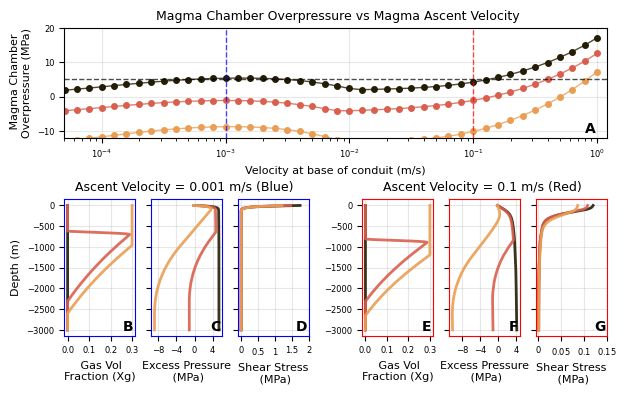

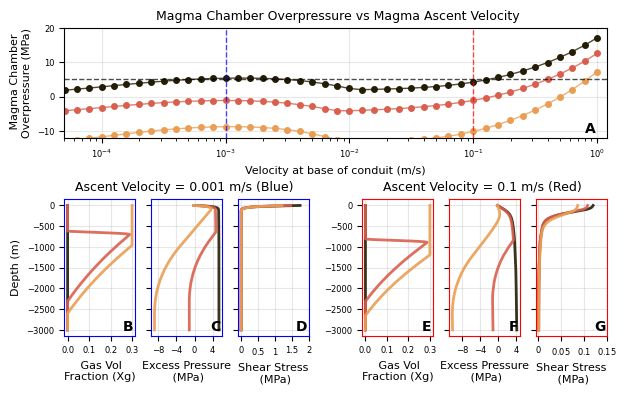

In [6]:
#Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')

print(print(df[(df['U_in'] == 0.1) & (df['z'] == -3000)]))
#import pdb; pdb.set_trace()
plot_conduit_analysis_fig2(df, colormap='batlow', figsize=(7, 4), save_plot=True)




In [7]:

# ...existing code...

import matplotlib.patches as mpatches

def plot_conduit_analysis_fig2_presentation(df, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })
    # move xtick labels closer to the axis for top and bottom-row axes
  
    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': r'$X_g$',
        'P_excess': r'$\Delta P$ (MPa)',
        'spf.mu*spf.sr': r'$\tau$ (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = color_list = ['#0072B2', '#D55E00', '#009E73']
    sb_labels = {0: '100% Gas Loss', 4: 'Step at Xg = 0.3', 6: 'Sustained at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(2, n_vars*2+1, height_ratios=[0.65] + [1]*1,#n_sb_options, 
                          width_ratios=[1]*n_vars + [0.3] + [1]*n_vars, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=1.4, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    bottom_axes = []
    for i in range(3):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
    # Skip gs[1, 3] (the gap)
    for i in range(4, 7):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
            
    main_axes.append(top_ax)
    main_axes.append(bottom_axes)
    # Plot main data

    selected_velocities = [0.001, 0.1]
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        for n, velocity in enumerate(selected_velocities):
            constant_row = n * n_vars
            for j, (var, var_name) in enumerate(variables.items()):
                ax = main_axes[1][constant_row + j]
                #import pdb;pdb.set_trace()
                # Special handling for 1-Sb - plot in same colors as bottom row
                if var == '1-Sb':
                    
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=2, alpha=0.9)
                else:
                    # Plot other variables with colormap
                    
                        data_subset = df_filtered[df_filtered['U_in'] == velocity]
                        
                        if not data_subset.empty and var in data_subset.columns:
                            # Sort by depth for proper line plotting
                            data_subset = data_subset.sort_values('z')
                            depth = data_subset['z']
                            
                            # Get color based on velocity using log scale
                            #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                            color = sb_to_color[sb_option]
                            if var in ['spf.mu*spf.sr', 'P_excess']:
                                plot_vals = data_subset[var] / 1e6
                                x_label = var_name.replace('(Pa)', '(MPa)')
                            elif var == 'Cw':
                                plot_vals = data_subset[var] * 100  # Convert to wt%
                                

                            else:
                                plot_vals = data_subset[var]
                                x_label = var_name
                            ax.plot(plot_vals, depth/1e3, color=color, linewidth=2, alpha=0.9)
                                        
                
                        # Set logarithmic scale for shear stress and magma viscosity only
                if var in [ 'mu_mbc','mu_m','nu_c']:
                    ax.set_xscale('log')
                if ax.get_xscale() == 'log':
                    pass
                else:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
                
                if var == 'Cw':
                    ax.set_xticks([0, 1, 2, 3])
                    ax.set_xticklabels(['0', '1', '2', '3'])
                elif var == 'spf.mu*spf.sr':
                    if n==1:
                        ticks = [0, 0.15]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0',r'$0.15$']) 
                    else:
                        ticks = [0,2]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0',2])
                elif var == 'Xg':
                
                    ticks = [0, 0.3]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'0',r'$0.3$']) 
                 
                
                elif var == 'nu_c':
                    ticks = [1, 1e2, 1e4]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
                # Reverse y-axis (depth increases downward)
                #ax.invert_yaxis()
                
                # Set labels and formatting
                # Always show x-axis labels and ticks, even for shared x-axes
                ax.set_xlabel(var_name)
                ax.tick_params(axis='x', labelbottom=True)
                if j == 0:  # Left column
                    ax.set_ylabel(f"Depth (km)",labelpad=12)#\n{sb_labels.get(sb_option, f'{sb_option}')}")
                else:
                    ax.set_ylabel("")
                    # Hide y-tick labels for non-leftmost plots
                    ax.set_yticklabels([])
                
                ax.grid(True, alpha=0.3)
                
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    
    # bbox0 = main_axes[1][0].get_position()
    # bbox2 = main_axes[1][2].get_position()
    # x0 = bbox0.x0
    # y0 = bbox0.y0
    # x1 = bbox2.x1
    # y1 = bbox0.y1


# raise/move axis titles (x labels on top, and y labels vertically centered)


    main_axes[1][4].set_title('Ascent Velocity = 0.1 m/s', y=-0.22,color='red')
    main_axes[1][1].set_title('Ascent Velocity = 0.001 m/s', y=-0.22,color='blue')
    for j, ax in enumerate(main_axes[1]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        ax.xaxis.set_ticks_position('top')
        ax.xaxis.set_label_position('top')
        # for spine in ax.spines.values():
        #     spine.set_linewidth(2)
        # Remove top and right spines for a cleaner look
        ax.spines['bottom'].set_visible(False)
        ax.spines['right'].set_visible(False)
        # Add a shared y-label for the bottom row (centered vertically)
        # #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)
        # for spine in ax.spines.values():
        #     if j>=3:
        #         spine.set_edgecolor('red')
        #     else:
        #         spine.set_edgecolor('blue')
        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[1]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    

    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.95, linewidth=3)
        #for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
        #    print(c)
        #    top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], linestyle='-',linewidth=3, label=sb_to_label[sb_option])
        )

    
    top_ax.set_ylabel(r'Inlet $\Delta P$(MPa)',labelpad=1)
    top_ax.set_title(' Outgassing models: Inlet Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)

    
    top_ax.set_xlabel('Inlet Velocity (m/s)', labelpad=1)  # Move xlabel closer
    top_ax.tick_params(axis='x', pad=1) 
    top_ax.tick_params(axis='y', pad=1) 
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa

    top_ax.set_ylim(-15, 15)
    
    top_ax.set_xlim([5e-5,1.2])
    # place a centered 3-column legend immediately below the top axis
    top_pos = top_ax.get_position()
    legend_y = top_pos.y0 - 0.075   # adjust -0.03 if you need more/less gap
    fig.legend(
        handles=legend_handles,
        title='Outgassing Model',
        ncol=3,
        fontsize=10,
        title_fontsize=11,
        loc='upper center',
        bbox_to_anchor=(0.5, legend_y),
        frameon=True
    )
    top_ax.spines['top'].set_visible(False)
    top_ax.spines['right'].set_visible(False)
    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right'
    )
    for ax in main_axes[1]:
        # If x-label is on top, push it further up (axis coords: x=0..1, y relative to axis box)
        if ax.xaxis.get_label_position() == 'top':
            ax.xaxis.set_label_coords(0.5, 1.22)   # center horizontally, raise vertically (tweak 1.06..1.12)
  
        # Move y-label a bit outward and keep it vertically centered
        #ax.yaxis.set_label_coords(-0.12, 0.5)  
    for ax in [top_ax] + main_axes[1]:
        ax.tick_params(axis='x', which='both', pad=0)   # 0 = very close; use small positive or negative to tweak
        ax.xaxis.labelpad = 0                           # tighten xlabel distance
    # also tighten global default (optional)
    import matplotlib as mpl
    mpl.rcParams['xtick.major.pad'] = 0
    label_idx += 1
    # Then label the main grid subplots as B, C, ...
    for i, ax in enumerate(main_axes[1]):
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right'
        )
        label_idx += 1
    fig.savefig(f'figure2_conduit_analysis_Colima_Sb_comparison_flow_only_june26.pdf', dpi=300, bbox_inches='tight')
    fig.savefig(f'figure2_conduit_analysis_Colima_Sb_comparison_flow_only_new_june26.svg', dpi=300, bbox_inches='tight')

    return fig



Creating conduit analysis plot...
           r       z  U_in  Sb_option  Xc_nocap   Xc   Sb   Xg  spf.mu*spf.sr  \
50040   15.0 -3000.0   0.1          0       0.3  0.3  0.0  0.0         997.61   
163801  15.0 -3000.0   0.1          4       0.3  0.3  1.0  0.0         997.61   
241341  15.0 -3000.0   0.1          6       0.3  0.3  1.0  0.0         997.61   

         rho_b  ...   Xm       T         P_e   linproj_r     mu_m  nu_b_inf  \
50040   2700.0  ...  0.7  1273.0  86279000.0  86279000.0  13468.0       1.0   
163801  2700.0  ...  0.7  1273.0  80941000.0  80941000.0  13468.0       1.0   
241341  2700.0  ...  0.7  1273.0  71864000.0  71864000.0  13468.0       1.0   

          nu_c   mu_mbc  u_av    Cw  
50040   2.7778  37410.0   0.1  0.03  
163801  2.7778  37410.0   0.1  0.03  
241341  2.7778  37410.0   0.1  0.03  

[3 rows x 21 columns]
None
axes.labelsize: 11.0
axes.titlesize: 11.0
xtick.labelsize: 9.5
ytick.labelsize: 9.5
legend.fontsize: 11.0
figure.titlesize: 11.0
11.0
Debug: z 

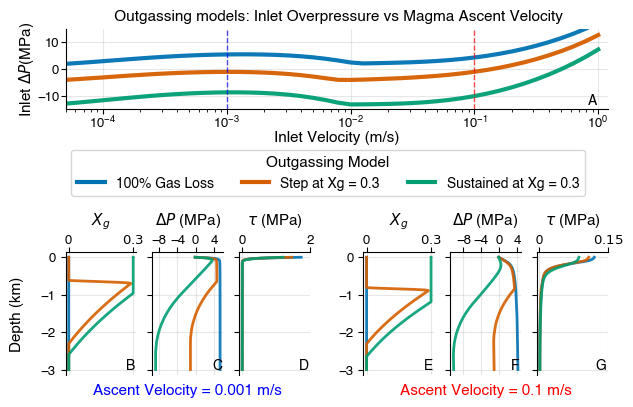

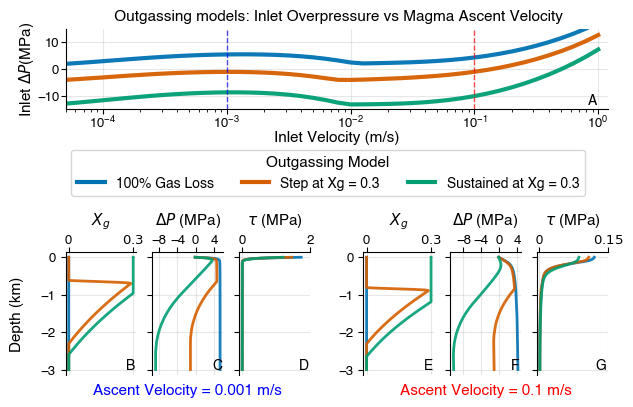

In [8]:
#Create the specific conduit analysis plot
print(f"\nCreating conduit analysis plot...")
#plot_conduit_analysis(df, colormap='gnuplot')

print(print(df[(df['U_in'] == 0.1) & (df['z'] == -3000)]))
#import pdb; pdb.set_trace()
plot_conduit_analysis_fig2_presentation(df, colormap='batlow', figsize=(7, 4.5), save_plot=True)




In [10]:

def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['r','z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                print('loop start')
                #print(f"Processing param: {param}")
                print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    
                    r = raw_row['r']
                    z = raw_row['z']

                    output_df.at[row_idx, 'r'] = r
                    output_df.at[row_idx, 'z'] = z
                    
                    for var_name in var_names:
                        print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df






In [11]:
ge_fp_sb_0 = r'GE_out_inDEC01_2025_std19_ground_edge_sol347_CR15_Sb0_T_1273.txt'


ge_fp_sb_4 = r'GE_out_inDEC01_2025_std19_ground_edge_sol347_CR15_Sb4_T_1273.txt'

ge_fp_sb_6 = r'GE_out_inDEC01_2025_std19_ground_edge_sol347_CR15_Sb6_T_1273.txt'



In [12]:

filepath = ge_fp_sb_0
var_names = ['U_in', 'melt', 'h2oc', 'C_R', 'T', 'nu_c_max', 'Sb_option', 'param_def']
df_ge_test0 = parse_comsol_edge_data(filepath,var_names)

filepath = ge_fp_sb_4
df_ge_test4 = parse_comsol_edge_data(filepath,var_names)
filepath = ge_fp_sb_6
df_ge_test6 = parse_comsol_edge_data(filepath,var_names)
df_ge_test = pd.concat([df_ge_test0, df_ge_test4, df_ge_test6], ignore_index=True)

df_ge = pd.concat([df_ge_test0, df_ge_test4, df_ge_test6], ignore_index=True)
#df_ge = pd.concat([df_ge_Sb0, df_ge_Sb4, df_ge_Sb6], ignore_index=True)

['r', 'z', 'u2 (m)', 'v2 (m)', 'w2 (m)', 'solid.RotrZ (rad)', 'U_in', 'melt', 'h2oc', 'C_R', 'T', 'nu_c_max', 'Sb_option', 'param_def']
Number of rows in new dataframe
9027
Number of unique variables: (153, 8)
loop start
Processing param: u2 (m)
0 U_in
0 melt
0 h2oc
0 C_R
0 T
0 nu_c_max
0 Sb_option
0 param_def
1 U_in
1 melt
1 h2oc
1 C_R
1 T
1 nu_c_max
1 Sb_option
1 param_def
2 U_in
2 melt
2 h2oc
2 C_R
2 T
2 nu_c_max
2 Sb_option
2 param_def
3 U_in
3 melt
3 h2oc
3 C_R
3 T
3 nu_c_max
3 Sb_option
3 param_def
4 U_in
4 melt
4 h2oc
4 C_R
4 T
4 nu_c_max
4 Sb_option
4 param_def
5 U_in
5 melt
5 h2oc
5 C_R
5 T
5 nu_c_max
5 Sb_option
5 param_def
6 U_in
6 melt
6 h2oc
6 C_R
6 T
6 nu_c_max
6 Sb_option
6 param_def
7 U_in
7 melt
7 h2oc
7 C_R
7 T
7 nu_c_max
7 Sb_option
7 param_def
8 U_in
8 melt
8 h2oc
8 C_R
8 T
8 nu_c_max
8 Sb_option
8 param_def
9 U_in
9 melt
9 h2oc
9 C_R
9 T
9 nu_c_max
9 Sb_option
9 param_def
10 U_in
10 melt
10 h2oc
10 C_R
10 T
10 nu_c_max
10 Sb_option
10 param_def
11 U_in
11 melt
11 h

In [16]:


from matplotlib import gridspec


def plot_conduit_analysis_fig2_with_ground_deformation(df, df_ge, colormap='batlow', figsize=(20, 14), save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })
    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': ' Gas Vol\nFraction (Xg)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
    sb_labels = {0: '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(5, n_vars*2+1, height_ratios=[0.8] + [1]*1+[0.8]*3, #n_sb_options, 
                          width_ratios=[1]*n_vars + [0.3] + [1]*n_vars, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=0.5, wspace=0.25)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    bottom_axes = []
    for i in range(3):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)
    # Skip gs[1, 3] (the gap)
    for i in range(4, 7):
        ax = fig.add_subplot(gs[1, i])
        bottom_axes.append(ax)

    axes_last3 = []
    
    for i in range(3):
        sub_gs = gridspec.GridSpecFromSubplotSpec(
            1, 3, subplot_spec=gs[2+i, :], wspace=0.25
        )
        sub_ax = []
        for j in range(3):
            
            if i ==1:
                ax = fig.add_subplot(sub_gs[0, j], sharey=axes_last3[0][j])
            else:
                ax = fig.add_subplot(sub_gs[0, j])
            sub_ax.append(ax)
        axes_last3.append(sub_ax)
     
    main_axes.append(top_ax)
    main_axes.append(bottom_axes)
    main_axes.extend(axes_last3)
    
    # Plot main data

    selected_velocities = [0.1, 0.001]

    markers = ['-','--','-.']
    for i, sb_option in enumerate(sb_options):
        # Filter data for this sb_option
        df_filtered = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        for n, velocity in enumerate(selected_velocities):
            constant_row = n * n_vars
            for j, (var, var_name) in enumerate(variables.items()):
                ax = main_axes[1][constant_row + j]
                
                #import pdb;pdb.set_trace()
                # Special handling for 1-Sb - plot in same colors as bottom row
                if var == '1-Sb':
                    
                    data_subset = df_filtered[df_filtered['U_in'] == velocity]
                    if not data_subset.empty and '1-Sb' in data_subset.columns:
                        # Sort by depth for proper line plotting
                        data_subset = data_subset.sort_values('z')
                        depth = data_subset['z']
                        # Use the same color as in bottom row for this Sb_option
                        color = sb_to_color[sb_option]
                        ax.plot(data_subset['1-Sb'], depth, 
                                color=color, 
                                linewidth=1.5, linestyle=markers[j], alpha=0.9)
                else:
                    # Plot other variables with colormap
                    
                        data_subset = df_filtered[df_filtered['U_in'] == velocity]
                        
                        if not data_subset.empty and var in data_subset.columns:
                            # Sort by depth for proper line plotting
                            data_subset = data_subset.sort_values('z')
                            depth = data_subset['z']
                            
                            # Get color based on velocity using log scale
                            #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                            color = sb_to_color[sb_option]
                            if var in ['spf.mu*spf.sr', 'P_excess']:
                                plot_vals = data_subset[var] / 1e6
                                x_label = var_name.replace('(Pa)', '(MPa)')
                            elif var == 'Cw':
                                plot_vals = data_subset[var] * 100  # Convert to wt%
                                

                            else:
                                plot_vals = data_subset[var]
                                x_label = var_name
                            ax.plot(plot_vals, depth, color=color, linewidth=1.5, linestyle=markers[j], alpha=0.9)
                                        
                
                        # Set logarithmic scale for shear stress and magma viscosity only
                if var in [ 'mu_mbc','mu_m','nu_c']:
                    ax.set_xscale('log')
                if ax.get_xscale() == 'log':
                    pass
                else:
                    ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
                
                if var == 'Cw':
                    ax.set_xticks([0, 1, 2, 3])
                    ax.set_xticklabels(['0', '1', '2', '3'])
                elif var == 'spf.mu*spf.sr':
                    if n==1:
                        ticks = [0, 0.5, 1,1.5,2]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.5$', r'$1$',1.5,2])
                    else:
                        ticks = [0,0.05, 0.1, 0.15]
                        ax.set_xticks(ticks)
                        ax.set_xticklabels([r'0', r'$0.05$', r'$0.1$', r'$0.15$'])    
                elif var == 'nu_c':
                    ticks = [1, 1e2, 1e4]
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([r'$1$', r'$10^{2}$', r'$10^{4}$'])
                # Reverse y-axis (depth increases downward)
                #ax.invert_yaxis()
                
                # Set labels and formatting
                # Always show x-axis labels and ticks, even for shared x-axes
                ax.set_xlabel(var_name)
                ax.tick_params(axis='x', labelbottom=True)
                if j == 0:  # Left column
                    ax.set_ylabel(f"Depth (m)")#\n{sb_labels.get(sb_option, f'{sb_option}')}")
                else:
                    ax.set_ylabel("")
                    # Hide y-tick labels for non-leftmost plots
                    ax.set_yticklabels([])
                
                ax.grid(True, alpha=0.3)
                
            # Set title only for top row
            #if i == 0:
                #ax.set_title(var_name)
    

  



    bottom_row = 1

    main_axes[bottom_row][1].set_title('Ascent Velocity = 0.1 m/s (Blue) ')
    main_axes[bottom_row][4].set_title('Ascent Velocity = 0.001 m/s (Red) ')
    for j, ax in enumerate(main_axes[bottom_row]):
        # Check if x-axis is log scale
         # Choose 3 ticks: min, geometric mean, max
        
        # Add a shared y-label for the bottom row (centered vertically)
        #fig.text(0.04, 0.5, "Depth (m)", va='center', rotation='vertical', fontsize=8)
        for spine in ax.spines.values():
            if j>=3:
                spine.set_edgecolor('red')
            else:
                spine.set_edgecolor('blue')
        # Optionally, remove individual y-labels from all but the first subplot in the bottom row
        for j, ax in enumerate(main_axes[bottom_row]):
            if j != 0:
                ax.set_ylabel("")
    # Add colorbar for the main plots (excluding Sb)
    # Create a ScalarMappable for the colorbar with log normalization
    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # Plot P_excess at deepest depth vs U_in for each Sb_option
    sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                if len(velocities_plot) <= 3:
                    print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.8, linewidth=1)
        for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            print(c)
            top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        legend_handles.append(
            plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        )

    label_ys = [0.8,0.5,0.2]  # y-position for the label (adjust as needed)
    label_x = 0.003  # x-positions for each label (adjust as needed)
    for idx, sb_option in enumerate(sb_options):
        top_ax.text(
            label_x, label_ys[idx], sb_to_label[sb_option],
            color=sb_to_color[sb_option],
            fontsize=8, fontweight='bold', va='bottom', ha='left',
            transform=top_ax.get_xaxis_transform()
        )
    top_ax.set_xlabel('Velocity at base of conduit (m/s)')
    top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
    top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa
    #top_ax.axhline(2, color='black', linestyle='--', linewidth=1, alpha=0.7)
    #top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.set_ylim(-12, 15)
    #top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    top_ax.set_xlim([5e-5,0.5])
 
    # Displacement plots from ground deformation data
    axes_last3_names = ['Vertical\nDisplacement (mm)', 'Radial\nDisplacement (mm)', 'Tilt (urad)']
    disp_Z_ax =axes_last3[0]
    disp_R_ax =axes_last3[1]
    disp_tilt_ax =axes_last3[2]
    print(str(len(axes_last3))+' axes for displacement plots')
    gps_distances = [100, 500, 1000]  # in meters
    unique_sb = [0,4,6]
    unique_param_def = [0,2]
    line_style = ['-.','--']

    ylim_for_row0 = [(-5,15), (-1,5), (-1,3)]
    for i, (ax_list, disp_var, disp_name) in enumerate(zip(axes_last3, 
                                                     ['w2', 'u2', 'solid.RotrZ'],
                                                     axes_last3_names)):
        
        
        for j,station_distance in enumerate(gps_distances):
            if i<2:
                ax_list[j].set_ylim(ylim_for_row0[j])
            ax_list[j].text(
                0.02, 0.98, f'Displacement at {station_distance} m',
                transform=ax_list[j].transAxes,
                fontsize=9, fontweight='normal', va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
                )
            #ax_list[j].set_title(f'Displacement at {station_distance} m ')
            
            if j == 0:
                ax_list[j].set_ylabel(disp_name)
            ax_list[j].grid(True, alpha=0.3)
            for k,param_def in enumerate(unique_param_def):
                for sb in unique_sb:
                    colour = sb_to_color[sb]
                    x = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)]['U_in']
                    if disp_var=='solid.RotrZ':
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e6
                    else:   
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==station_distance)&(df_ge['param_def']==param_def)][disp_var]*1e3
                    ax_list[j].semilogx(x,y,c=colour,linestyle=line_style[k],linewidth=1, alpha = 0.75,label=f'Sb={sb}, param_def={param_def}')
                    ax_list[j].set_xlim([5e-5,0.5])
                    
                    pass



    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.02, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right',
        bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...
    for i, ax in enumerate(main_axes[1]):
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line

        )
        label_idx += 1
    
   




    for ax in disp_Z_ax+disp_R_ax+disp_tilt_ax:
        ax.text(
            0.98, 0.02, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
        )
        label_idx += 1


    #fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt.png', dpi=300, bbox_inches='tight')
    #fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt.pdf', dpi=300, bbox_inches='tight')

    return fig


AI generated new plotting

In [29]:
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import string

def plot_conduit_analysis_fig2_with_ground_deformation_presentation(
    df,
    df_ge,
    colormap='batlow',
    figsize=(10, 9),
    save_plot=True
):
    """
    Plot ground deformation response at three distances from the conduit using
    the presentation styling from plot_conduit_analysis_fig2_presentation.

    Layout:
    - 3 columns: distances from conduit
    - 3 rows: vertical displacement, radial displacement, tilt
    """

    mpl.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
        'font.size': 11,
        'axes.labelsize':11,
        'axes.titlesize': 11,
        'xtick.labelsize': 9.5,
        'ytick.labelsize': 9.5,
        'legend.fontsize': 11,
        'figure.titlesize': 11
    })

    df_analysis = calculate_excess_pressure(df)
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']

    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues

    sb_colors = ['#0072B2', '#D55E00', '#009E73']
    sb_labels = {
        0: '100% Gas Loss',
        4: 'Step at Xg = 0.3',
        6: 'Sustained at Xg = 0.3'
    }

    sb_options = [sb for sb in [0, 4, 6] if sb in df_analysis['Sb_option'].unique()]
    sb_to_color = {sb_option: sb_colors[i % len(sb_colors)] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}

    distances = [100, 500, 1000]
    row_specs = [
        ('w2', '$u_z$ (mm)'),
        ('u2', '$u_r$ (mm)'),
        ('solid.RotrZ', r'Tilt ($\mu rad$)'),
    ]

    fig, axes = plt.subplots(
        3, 3,
        figsize=figsize,
        sharex='col',
        #sharey='row'
    )

    fig.subplots_adjust(
        left=0.06,
        right=0.98,
        bottom=0.06,
        top=0.92,
        wspace=0.15,
        hspace=0.2,
    )

    for col, r_from_cond in enumerate(distances):
        for row, (disp_var, disp_name) in enumerate(row_specs):
            ax = axes[row, col]
           
            specific_velocities = list(reversed([1, 0.1, 1e-2, 1e-3, 1e-4, 1e-5]))
            labels = list(reversed([r'$10^{0}$', r'$10^{-1}$', r'$10^{-2}$', r'$10^{-3}$', r'$10^{-4}$', r'$10^{-5}$']))
            ax.set_xticks(specific_velocities)
            ax.set_xticklabels(labels)
            ax.set_xlim([5e-5,1.2])
            for k,param_def in enumerate([0,2]):
                for sb in sb_options:
                    mask = (
                        (df_ge['Sb_option'] == sb) &
                        (df_ge['r'] == r_from_cond)
                    )

                    if 'param_def' in df_ge.columns:
                        mask = mask & (df_ge['param_def'] == param_def)

                    data = df_ge.loc[mask].sort_values('U_in')
                    if data.empty or disp_var not in data.columns:
                        continue

                    x = data['U_in'].to_numpy()
                    if disp_var == 'solid.RotrZ':
                        y = data[disp_var].to_numpy() * 1e6
                    else:
                        y = data[disp_var].to_numpy() * 1e3
                    if param_def == 0:
                        linestyle = 'dotted'
                    else:                        
                        linestyle = 'dashed'   
                    ax.semilogx(
                        x,
                        y,
                        color=sb_to_color[sb],
                        linewidth=2,
                        linestyle=linestyle,    
                        alpha=0.85,
                    )

            ax.grid(True, alpha=0.3)

            if row == 0:
                ax.set_title(f'Displacement at {r_from_cond} m', pad=10)

            if col == 0:
                ax.set_ylabel(disp_name)
            else:
                ax.set_ylabel("")

            if row == 2:
                ax.set_xlabel('Velocity Inlet (m/s)', labelpad=6)
            else:
                ax.set_xlabel("")

            ax.tick_params(axis='x', which='both', pad=1)
            ax.tick_params(axis='y', which='both', pad=1)

            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)

    labels = list(string.ascii_uppercase)
    label_idx = 0
    for row in range(3):
        for col in range(3):
            axes[row, col].text(
                0.1,
                0.95,
                labels[label_idx],
                transform=axes[row, col].transAxes,
                fontsize=10,
                fontweight='bold',
                va='bottom',
                ha='right',
                bbox=dict(
                    facecolor='none',
                    edgecolor='none',
                    boxstyle='round,pad=0.2',
                    alpha=0.8
                )
            )
            label_idx += 1
    for ax in axes.flat:
        ax.tick_params(axis='x', which='both', labelbottom=True)

    fig.tight_layout(rect=[0, 0, 1, 0.92])
   # fig.suptitle("Your suptitle text", )
    fig.suptitle('Effect of Outgassing Model on Ground Deformation', fontsize=12,y=0.95, fontweight='bold')

    # legend_handles = [plt.Line2D([0], [0], color=sb_to_color[sb], lw=2, alpha=0.85) for sb in sb_options]
    # legend_labels = [sb_to_label[sb] for sb in sb_options]

    # # add black dotted/dashed entries for 'τ Only' and 'ΔP Only'
    # tau_handle = plt.Line2D([0], [0], color='k', lw=2, linestyle=':', alpha=0.9)
    # dp_handle  = plt.Line2D([0], [0], color='k', lw=2, linestyle='--', alpha=0.9)
    # legend_handles.extend([tau_handle, dp_handle])
    # legend_labels.extend([r'$\tau$ Only', r'$\Delta P$ Only'])

    # fig.subplots_adjust(bottom=0.16*2)  # make room for legend
    # fig.legend(
    #     handles=legend_handles,
    #     labels=legend_labels,
    #     ncol=3,
    #     loc='lower center',
    #     bbox_to_anchor=(0.5, -0.085),
    #     frameon=True,
    #     fontsize=9,
    #     title='Outgassing Model',
    #     title_fontsize=10
    # )

    # color legend (outgassing models)
    color_handles = [plt.Line2D([0],[0], color=sb_to_color[sb], lw=2, alpha=0.85) for sb in sb_options]
    color_labels  = [sb_to_label[sb] for sb in sb_options]

    # style legend (τ Only / ΔP Only)
    tau_handle = plt.Line2D([0],[0], color='k', lw=2, linestyle=':', alpha=0.9)
    dp_handle  = plt.Line2D([0],[0], color='k', lw=2, linestyle='--', alpha=0.9)
    style_handles = [tau_handle, dp_handle]
    style_labels  = [r'$\tau$ Only', r'$\Delta P$ Only']

    fig.subplots_adjust(bottom=0.22)  # make room for two legend rows
    fig.legend(handles=color_handles, labels=color_labels, ncol=3,
            loc='lower center', bbox_to_anchor=(0.5, -0.02),
            frameon=False, fontsize=9, title='Outgassing Model', title_fontsize=10)
    fig.legend(handles=style_handles,title='Deformation Source', labels=style_labels, ncol=2,
            loc='lower center', bbox_to_anchor=(0.5, -0.10),
            frameon=False, fontsize=9)
    
    if save_plot:
            fig.savefig(
                f'figure2_conduit_analysis_Colima_Sb_comparison_with_deformation_only_presentation_june26.png',
                dpi=300,
                bbox_inches='tight'
            )
            fig.savefig(
                f'figure2_conduit_analysis_Colima_Sb_comparison_with_deformation_only_presentation_june26.pdf',
                dpi=300,
                bbox_inches='tight')
            
    return fig

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2494100.0 to 99218000.0
Debug: P_excess range: -14828805.399999991 to 17157000.0


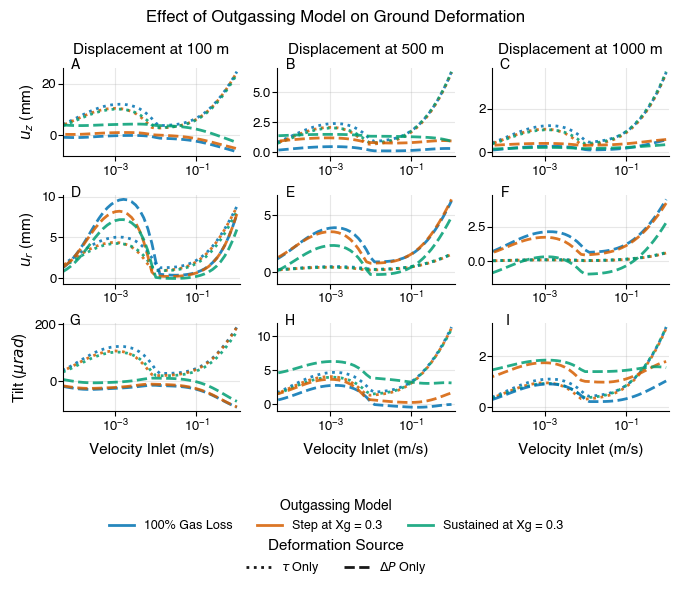

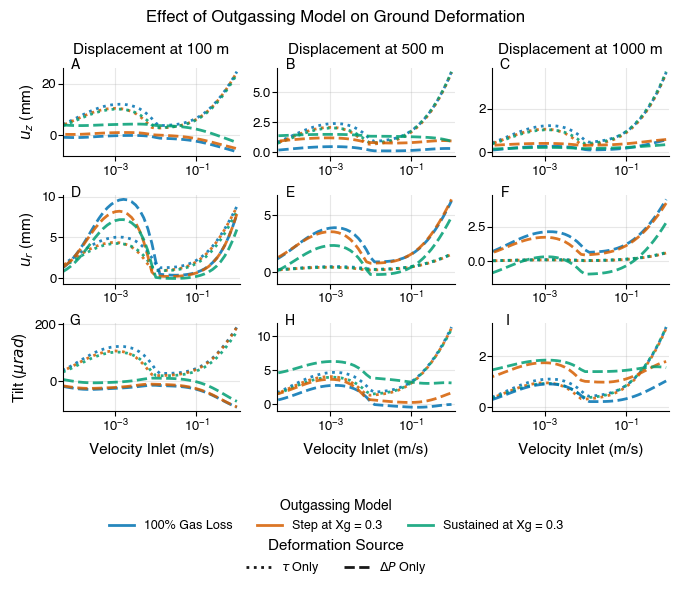

In [30]:
plot_conduit_analysis_fig2_with_ground_deformation_presentation(df, df_ge_test, colormap='batlow', figsize=(7, 5.5), save_plot=True)

In [107]:


from matplotlib import gridspec


def plot_conduit_analysis_fig2_with_ground_deformation_presentation(df, df_ge, colormap='batlow', figsize=(20, 14),r_from_cond = 100,save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.size': 8,
        'axes.labelsize': 8,
        'axes.titlesize': 9,
        'xtick.labelsize': 6,
        'ytick.labelsize': 6,
        'legend.fontsize': 7,
        'figure.titlesize': 10
    })

    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': ' Gas Vol\nFraction (Xg)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
    sb_labels = {0: '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(4, 1, height_ratios=[1]*4, hspace=0.3)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    # bottom_axes = []
    # for i in range(3):
    #     ax = fig.add_subplot(gs[1, i])
    #     bottom_axes.append(ax)
    # # Skip gs[1, 3] (the gap)
    # for i in range(4, 7):
    #     ax = fig.add_subplot(gs[1, i])
    #     bottom_axes.append(ax)

    axes_last3 = []
    
    
    sub_gs = gridspec.GridSpecFromSubplotSpec(
        1, 3, subplot_spec=gs[1, :], wspace=0.25
    )
    
    vert_ax = fig.add_subplot(gs[1, :],sharex=top_ax)
    rad_ax = fig.add_subplot(gs[2, :],sharex=top_ax)
    tilt_ax = fig.add_subplot(gs[3, :],sharex=top_ax)
  
    axes_last3.append(vert_ax)
    axes_last3.append(rad_ax)
    axes_last3.append(tilt_ax)
        
    
    main_axes.append(top_ax)
    #main_axes.append(bottom_axes)
    main_axes.extend(axes_last3)
    
    
    

    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # Plot P_excess at deepest depth vs U_in for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                #if len(velocities_plot) <= 3:
                    #print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.8, linewidth=2)
        #for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            #print(c)
        #   top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        # legend_handles.append(
        #     plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        # )

    label_ys = [0.8,0.5,0.2]  # y-position for the label (adjust as needed)
    label_x = 0.003  # x-positions for each label (adjust as needed)
    # for idx, sb_option in enumerate(sb_options):
    #     top_ax.text(
    #         label_x, label_ys[idx], sb_to_label[sb_option],
    #         color=sb_to_color[sb_option],
    #         fontsize=8, fontweight='bold', va='bottom', ha='left',
    #         transform=top_ax.get_xaxis_transform()
    #     )
    
    top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
    top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa
    #top_ax.axhline(2, color='black', linestyle='--', linewidth=1, alpha=0.7)
    #top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.set_ylim(-15, 15)
    #top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    top_ax.set_xlim([5e-5,0.5])
 
    # Displacement plots from ground deformation data
    axes_last3_names = ['Vertical\n(mm)', 'Radial\n (mm)', r'Tilt ($\mu rad$)']
    disp_Z_ax =axes_last3[0]
    disp_R_ax =axes_last3[1]
    disp_tilt_ax =axes_last3[2]
    print(str(len(axes_last3))+' axes for displacement plots')
    gps_distances = [r_from_cond]  # in meters
    unique_sb = [0,4,6]
    unique_param_def = [0,2]
    line_style = ['dotted','solid']

    ylim_for_row0 = [(-5,15), (-1,5), (-1,3)]
    for i, (ax_list, disp_var, disp_name) in enumerate(zip(axes_last3, 
                                                     ['w2', 'u2', 'solid.RotrZ'],
                                                     axes_last3_names)):
        
        
            if r_from_cond == 100:
    
                ax_list.set_ylim(ylim_for_row0[0])
            ax_list.text(
                0.02, 0.98, f'Displacement at {r_from_cond} m',
                transform=ax_list.transAxes,
                fontsize=9, fontweight='normal', va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
                )
            #ax_list[j].set_title(f'Displacement at {station_distance} m ')
            
            
            
            ax_list.set_ylabel(disp_name)
            
            ax_list.grid(True, alpha=0.3)
            for k,param_def in enumerate(unique_param_def):
                for sb in unique_sb:
                    colour = sb_to_color[sb]
                    x = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==r_from_cond)&(df_ge['param_def']==param_def)]['U_in']
                    if disp_var=='solid.RotrZ':
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==r_from_cond)&(df_ge['param_def']==param_def)][disp_var]*1e6
                    else:   
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==r_from_cond)&(df_ge['param_def']==param_def)][disp_var]*1e3
                    ax_list.semilogx(x,y,c=colour,linestyle=line_style[k],linewidth=2, alpha = 0.85,label=f'Sb={sb}, param_def={param_def}')
                    ax_list.set_xlim([5e-5,0.5])
                    
                    pass



    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.94, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right',
        bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...


    if r_from_cond == 100:
    
        disp_tilt_ax.set_ylim([-50,150])
   
    for ax in [disp_Z_ax, disp_R_ax, disp_tilt_ax]:
        ax.text(
            0.98, 0.94, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
        )
        label_idx += 1
        ax.spines['bottom'].set_position(('data', 0))
        ax.xaxis.set_ticks_position('bottom')
        ax.xaxis.set_label_position('bottom')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        if r_from_cond == 1000:
            ax.set_ylim([-1,2.5])

    disp_tilt_ax.set_xlabel('Velocity Inlet (m/s)')
    fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt_presentation_r{r_from_cond}.pdf', dpi=300, bbox_inches='tight')
    fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt_presentation_r{r_from_cond}.png', dpi=300, bbox_inches='tight')

    return fig


axes.labelsize: 8.0
axes.titlesize: 9.0
xtick.labelsize: 6.0
ytick.labelsize: 6.0
legend.fontsize: 7.0
figure.titlesize: 10.0
8.0


Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2494100.0 to 99218000.0
Debug: P_excess range: -14828805.399999991 to 17157000.0
3 axes for displacement plots


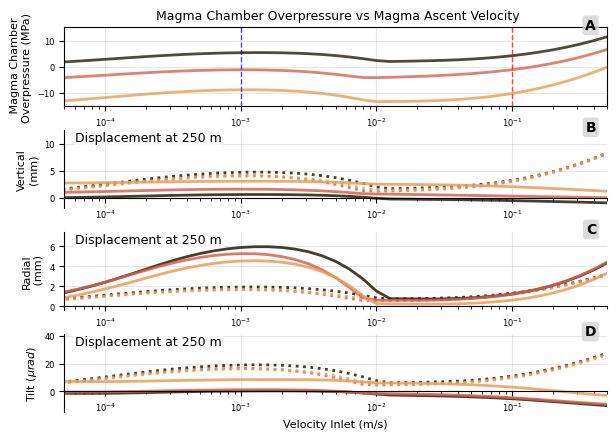

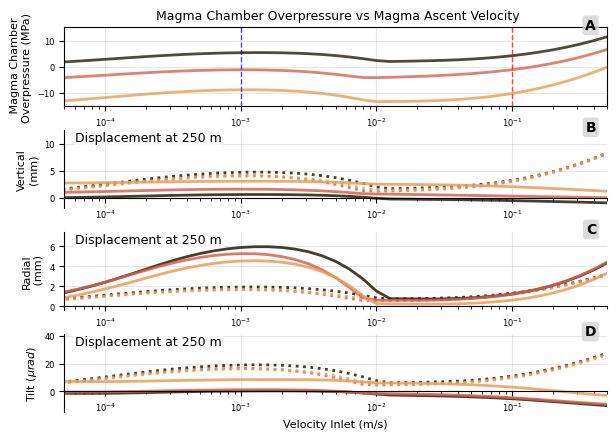

In [30]:
plot_conduit_analysis_fig2_with_ground_deformation_presentation(df, df_ge_test, colormap='batlow', figsize=(7, 5),r_from_cond = 250, save_plot=True)

In [34]:


from matplotlib import gridspec


def plot_conduit_analysis_fig2_with_ground_deformation_presentation_2(df, df_ge, colormap='batlow', figsize=(20, 14),r_from_cond = 100,save_plot=True):
    """
    Plot conduit analysis variables: Xc, rho_b, P_excess, Shear Stress, nu_magma, and Sb.
    Plus a Top row showing P_excess at deepest depth vs velocity.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
    colormap : str
        Name of cmcrameri colormap to use (default: 'batlow')
    figsize : tuple
        Figure size for the entire plot
    save_plot : bool
        Whether to save plot to file
    """
        # Suppose main_axes is a 2D list: main_axes[row][col]
    from matplotlib.ticker import MaxNLocator, LogLocator
    import matplotlib as mpl
    mpl.rcParams.update({
        'font.size': 8,
        'axes.labelsize': 8,
        'axes.titlesize': 9,
        'xtick.labelsize': 6,
        'ytick.labelsize': 6,
        'legend.fontsize': 7,
        'figure.titlesize': 10
    })

    print("axes.labelsize:", mpl.rcParams['axes.labelsize'])      # Axis label font size
    print("axes.titlesize:", mpl.rcParams['axes.titlesize'])      # Axis title font size
    print("xtick.labelsize:", mpl.rcParams['xtick.labelsize'])    # X tick label font size
    print("ytick.labelsize:", mpl.rcParams['ytick.labelsize'])    # Y tick label font size
    print("legend.fontsize:", mpl.rcParams['legend.fontsize'])    # Legend font size
    print("figure.titlesize:", mpl.rcParams['figure.titlesize'])  # Figure suptitle font size
    
    print(mpl.rcParams['font.size'])  
    # Calculate P_excess
    df_analysis = calculate_excess_pressure(df)
    
    # Add (1-Sb) column for plotting
    if 'Sb' in df_analysis.columns:
        df_analysis['1-Sb'] = 1 - df_analysis['Sb']
    # Define variables to plot with their display names
    variables = {
        'Xg': ' Gas Vol\nFraction (Xg)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }
    

    #exctract_points_1e-3 = {0:1e-3,4:1e-3,6:1e-3}

    #extract_points_1e-1 = {0:1e-1,4:1e-1,6:1e-1}


    # Get unique sb_options and sort them
    sb_options = sorted(df_analysis['Sb_option'].unique())
    n_sb_options = len(sb_options)
    n_vars = len(variables)
    
    # Define colors for each Sb_option using 3 shades of blue from oslo colormap
    try:
        oslo_cmap = cmc.lajolla
    except AttributeError:
        oslo_cmap = plt.cm.Blues
    sb_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
    sb_labels = {0: '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
    sb_to_color = {sb_option: sb_colors[i % 3] for i, sb_option in enumerate(sb_options)}
    sb_to_label = {sb_option: sb_labels.get(sb_option, f'Sb = {sb_option}') for sb_option in sb_options}
    
    # Get unique velocities (use all data to get full range)
    velocities = sorted(df_analysis['U_in'].unique())
    n_velocities = len(velocities)
    
    # Create velocity to color mapping using log scale
    import numpy as np
    log_velocities = np.log10(velocities)
    log_min, log_max = log_velocities.min(), log_velocities.max()
    velocity_to_color = {vel: (np.log10(vel) - log_min) / (log_max - log_min) 
                        for vel in velocities}
    
    # Get the colormap (cmcrameri or matplotlib)
    cmap = get_colormap(colormap)
    
    # Create subplots: main grid + bottom row for P_excess vs U_in
    fig = plt.figure(figsize=figsize)
    
    # Create main grid (n_sb_options x n_vars)
    gs = fig.add_gridspec(4, 1, height_ratios=[1]*4, hspace=0.3)
    
    # Create main subplot grid with shared x-axes in each column
    main_axes = []
    # Top row (span all columns)
    top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
    # bottom_axes = []
    # for i in range(3):
    #     ax = fig.add_subplot(gs[1, i])
    #     bottom_axes.append(ax)
    # # Skip gs[1, 3] (the gap)
    # for i in range(4, 7):
    #     ax = fig.add_subplot(gs[1, i])
    #     bottom_axes.append(ax)

    axes_last3 = []
    
    
    sub_gs = gridspec.GridSpecFromSubplotSpec(
        1, 3, subplot_spec=gs[1, :], wspace=0.25
    )
    
    vert_ax = fig.add_subplot(gs[1, :],sharex=top_ax)
    rad_ax = fig.add_subplot(gs[2, :],sharex=top_ax)
    tilt_ax = fig.add_subplot(gs[3, :],sharex=top_ax)
  
    axes_last3.append(vert_ax)
    axes_last3.append(rad_ax)
    axes_last3.append(tilt_ax)
        
    
    main_axes.append(top_ax)
    #main_axes.append(bottom_axes)
    main_axes.extend(axes_last3)
    
    
    

    from matplotlib.colors import LogNorm
    sm = plt.cm.ScalarMappable(cmap=cmap, 
                              norm=LogNorm(vmin=min(velocities), 
                                          vmax=max(velocities)))
    sm.set_array([])
    
    # Plot P_excess at deepest depth vs U_in for each Sb_option
    legend_handles = []
    for idx, sb_option in enumerate(sb_options):
        df_sb = df_analysis[df_analysis['Sb_option'] == sb_option].copy()
        p_excess_deepest = []
        velocities_plot = []
        colors_plot = []
        for velocity in velocities:
            df_vel = df_sb[df_sb['U_in'] == velocity]
            if not df_vel.empty:
                deepest_idx = df_vel['z'].idxmin()
                deepest_z = df_vel.loc[deepest_idx, 'z']
                deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
                deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
                p_excess_deepest.append(deepest_p_excess)
                # list to np array 
                
                velocities_plot.append(velocity)
                #if len(velocities_plot) <= 3:
                    #print(f"Sb_option {sb_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
                # Use the same normalization as sm (LogNorm)
                 # Get color based on velocity using log scale
                color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = cmap(color_index)
                colors_plot.append(color)

        p_excess_deepest = np.array(p_excess_deepest)/1e6
        # Plot each point with its color
        top_ax.semilogx(velocities_plot, p_excess_deepest, color=sb_to_color[sb_option], alpha=0.8, linewidth=2)
        #for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
            #print(c)
        #   top_ax.semilogx(v, p, marker='o', color=sb_to_color[sb_option], markersize=4, linewidth=0)       
        
        
        
        # top_ax.semilogx(velocities_plot, p_excess_deepest, 
        #         color=sb_to_color[sb_option],
        #         marker=sb_markers[idx % len(sb_markers)],
        #         markersize=8, linewidth=2, alpha=0.8,
        #         label=sb_to_label[sb_option])
        # legend_handles.append(
        #     plt.Line2D([], [], color=sb_to_color[sb_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=sb_to_label[sb_option])
        # )

    label_ys = [0.8,0.5,0.2]  # y-position for the label (adjust as needed)
    label_x = 0.003  # x-positions for each label (adjust as needed)
    # for idx, sb_option in enumerate(sb_options):
    #     top_ax.text(
    #         label_x, label_ys[idx], sb_to_label[sb_option],
    #         color=sb_to_color[sb_option],
    #         fontsize=8, fontweight='bold', va='bottom', ha='left',
    #         transform=top_ax.get_xaxis_transform()
    #     )
    
    top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
    top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
    top_ax.grid(True, alpha=0.3)
    # v line at 0.1 m/s and 0.001 m/s
    top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
    # set hline at 0 Mpa and 5 MPa
    #top_ax.axhline(2, color='black', linestyle='--', linewidth=1, alpha=0.7)
    #top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
    top_ax.set_ylim(-15, 15)
    #top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
    top_ax.set_xlim([5e-5,0.5])
 
    # Displacement plots from ground deformation data
    axes_last3_names = ['Vertical\n(mm)', 'Radial\n (mm)', r'Tilt ($\mu rad$)']
    disp_Z_ax =axes_last3[0]
    disp_R_ax =axes_last3[1]
    disp_tilt_ax =axes_last3[2]
    print(str(len(axes_last3))+' axes for displacement plots')
    gps_distances = [r_from_cond]  # in meters
    unique_sb = [0,4,6]
    unique_param_def = [1]
    line_style = ['solid']

    ylim_for_row0 = [(-5,15), (-1,5), (-1,3)]
    for i, (ax_list, disp_var, disp_name) in enumerate(zip(axes_last3, 
                                                     ['w2', 'u2', 'solid.RotrZ'],
                                                     axes_last3_names)):
        
        
            if r_from_cond == 100:
    
                ax_list.set_ylim(ylim_for_row0[0])
            ax_list.text(
                0.02, 0.98, f'Displacement at {r_from_cond} m',
                transform=ax_list.transAxes,
                fontsize=9, fontweight='normal', va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1)
                )
            #ax_list[j].set_title(f'Displacement at {station_distance} m ')
            
            
            
            ax_list.set_ylabel(disp_name)
            
            ax_list.grid(True, alpha=0.3)
            for k,param_def in enumerate(unique_param_def):
                for sb in unique_sb:
                    colour = sb_to_color[sb]
                    x = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==r_from_cond)&(df_ge['param_def']==param_def)]['U_in']
                    if disp_var=='solid.RotrZ':
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==r_from_cond)&(df_ge['param_def']==param_def)][disp_var]*1e6
                    else:   
                        y = df_ge[(df_ge['Sb_option'] == sb)&(df_ge['r']==r_from_cond)&(df_ge['param_def']==param_def)][disp_var]*1e3
                    ax_list.semilogx(x,y,c=colour,linestyle=line_style[k],linewidth=2, alpha = 0.85,label=f'Sb={sb}, param_def={param_def}')
                    ax_list.set_xlim([5e-5,0.5])
                    
                    pass



    import string

    labels = list(string.ascii_uppercase)  # ['A', 'B', 'C', ...]
    label_idx = 0

    # Label the top_ax as 'A'
    top_ax.text(
        0.98, 0.94, labels[label_idx],
        transform=top_ax.transAxes,
        fontsize=10,
        fontweight='bold',
        va='bottom', ha='right',
        bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
    )
    label_idx += 1

    # Then label the main grid subplots as B, C, ...


    if r_from_cond == 100:
    
        disp_tilt_ax.set_ylim([-50,150])
   
    for ax in [disp_Z_ax, disp_R_ax, disp_tilt_ax]:
        ax.text(
            0.98, 0.94, labels[label_idx],
            transform=ax.transAxes,
            fontsize=10,
            fontweight='bold',
            va='bottom', ha='right',
            bbox=dict(facecolor='lightgrey', edgecolor='none', boxstyle='round,pad=0.2', alpha=0.8)  # <-- Add this line
        )
        label_idx += 1
        ax.spines['bottom'].set_position(('data', 0))
        ax.xaxis.set_ticks_position('bottom')
        ax.xaxis.set_label_position('bottom')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        if r_from_cond == 1000:
            ax.set_ylim([-1,2.5])

    disp_tilt_ax.set_xlabel('Velocity Inlet (m/s)')
    fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt_presentation_r{r_from_cond}_new_param_def1.svg', dpi=300, bbox_inches='tight')
    fig.savefig(f'figure2_conduit_analysis_{colormap}_Colima_Sb_comparison_with_tilt_presentation_r{r_from_cond}.png', dpi=300, bbox_inches='tight')

    return fig


axes.labelsize: 8.0
axes.titlesize: 9.0
xtick.labelsize: 6.0
ytick.labelsize: 6.0
legend.fontsize: 7.0
figure.titlesize: 10.0
8.0


Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2494100.0 to 99218000.0
Debug: P_excess range: -14828805.399999991 to 17157000.0
3 axes for displacement plots


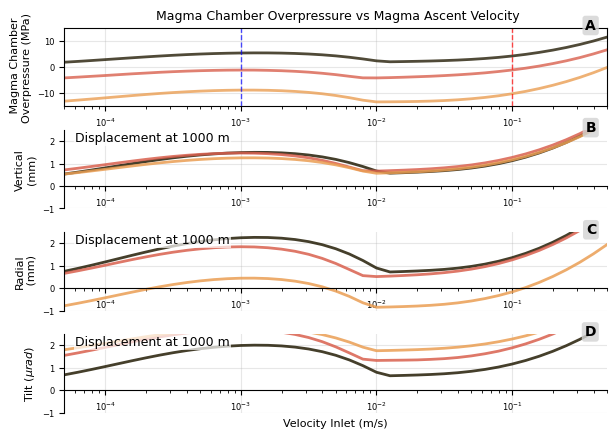

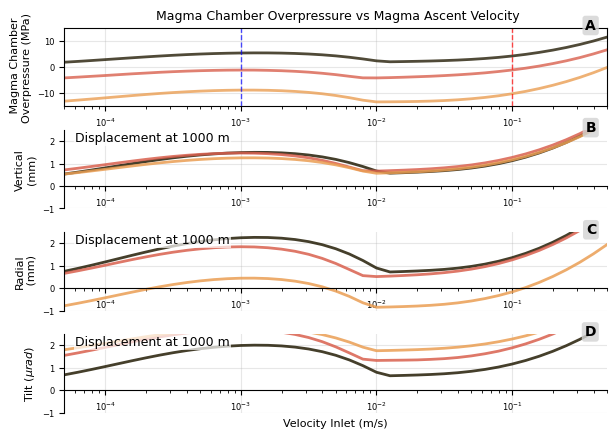

In [36]:
plot_conduit_analysis_fig2_with_ground_deformation_presentation_2(df, df_ge_test, colormap='batlow', figsize=(7, 5),r_from_cond = 1000, save_plot=True)